# t-SNE (t-distributed Stochastic Neighbor Embedding)
## Complete Practical Notebook

### Learning objectives
- Understand nonlinear dimensionality reduction and neighborhood preservation.
- Learn the roles of perplexity, learning rate, iterations, initialization, and random seed.
- Fit and visualize t-SNE with scikit-learn.
- Compare t-SNE with PCA and explore hyperparameter sensitivity.
- Interpret embeddings cautiously, especially in biological datasets.

> **Core idea:** t-SNE is primarily an exploratory visualization technique. Local neighborhoods are generally more meaningful than distances between far-apart groups.

## 1. Why t-SNE?

Datasets with dozens or thousands of features are difficult to visualize. Dimensionality reduction maps samples into two or three dimensions.

PCA is linear and emphasizes directions of high variance. **t-SNE is nonlinear** and aims to preserve local neighborhood relationships: samples that are neighbors in the original feature space should often remain neighbors in the embedding.

t-SNE is used to explore image embeddings, text representations, and high-dimensional biological measurements. It is not usually a general-purpose replacement for the original features.

## 2. Conceptual and Mathematical Overview

t-SNE converts pairwise similarities in the original space into probabilities. It then finds a low-dimensional embedding whose similarity distribution resembles the original one, using a Student's t-distribution in the embedding.

The objective minimizes Kullback–Leibler divergence:

$$
KL(P \parallel Q) = \sum_{i \ne j} p_{ij}\log\frac{p_{ij}}{q_{ij}}
$$

Here, $P$ represents similarities in the original space and $Q$ represents similarities in the embedding. This objective particularly penalizes original-space neighbors that are poorly represented in the embedding, so t-SNE emphasizes local structure.

## 3. Intuition: Similarity Probabilities and Crowding

Instead of preserving every distance directly, t-SNE estimates how likely samples are to be neighbors:
- Nearby samples receive higher similarity.
- Distant samples receive lower similarity.
- The embedding is optimized to approximate those similarities.

The Student's t-distribution has heavier tails than a Gaussian, helping alleviate the crowding problem when many high-dimensional points must be shown in only two dimensions.

## 4. Perplexity

Perplexity is a hyperparameter related to the effective number of neighbors considered for each sample. It is not exactly a fixed neighbor count.

Values such as 5, 15, 30, and 50 are often worth comparing, depending on dataset size. In scikit-learn, perplexity must be smaller than the number of samples.

Different values can produce noticeably different maps. Compare stability instead of choosing only the plot that looks most separated.

## 5. Learning Rate, Iterations, Initialization, and Randomness

- **Learning rate:** controls optimization step size; unsuitable values can yield poor layouts.
- **Iterations:** optimization may require many steps; inspect warnings and allow adequate iterations.
- **Initialization:** `init="pca"` starts from a PCA layout; `init="random"` starts randomly.
- **Random state:** helps reproduce a run, but does not guarantee identical results across all software versions and hardware.

Embeddings can rotate, flip, or shift without changing the essential neighborhood relationships.

## 6. Interpretation Rules

1. Nearby points often indicate similar local neighborhoods in the original representation.
2. Distances between well-separated groups are not reliable measures of dissimilarity.
3. Cluster size and density can be distorted.
4. Gaps do not automatically prove distinct populations.
5. Axes have no direct scientific meaning.
6. A t-SNE plot alone is not statistical evidence of a discovery.
7. Inspect preprocessing, metadata, and alternative parameter settings.

## 7. t-SNE vs PCA

| Property | PCA | t-SNE |
|---|---|---|
| Method | Linear | Nonlinear |
| Main emphasis | High-variance directions | Local neighborhood structure |
| Common use | Visualization and feature transformation | Exploratory visualization |
| New-sample transformation | `transform` is supported after fitting | Standard scikit-learn t-SNE has no conventional out-of-sample `transform` |
| Interpretation | Component directions can be inspected | Axes have no direct feature meaning |
| Global distances | Information is lost by projection | Distances between separated groups are easy to overinterpret |

PCA can be used before t-SNE for very high-dimensional data, but whether this helps depends on the dataset and goal.

## 8. Import Libraries

In [1]:
# Numerical operations and tabular data
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt

# Data generation, scaling, PCA, and t-SNE
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Use fixed random seeds for reproducible examples.
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 9. Create a Synthetic Dataset

In [2]:
# Generate 600 samples, five features, and four synthetic groups.
X, y = make_blobs(
    n_samples=600,
    n_features=5,
    centers=4,
    cluster_std=2.2,
    random_state=RANDOM_STATE
)

# Create readable feature names and a DataFrame for inspection.
feature_names = [f"feature_{i}" for i in range(1, X.shape[1] + 1)]
df = pd.DataFrame(X, columns=feature_names)

# Labels are used later only to color visualizations; t-SNE does not use them.
display(df.head())
print("Feature matrix shape:", X.shape)
print("Labels available for visualization:", len(y))

,feature_1,feature_2,feature_3,feature_4,feature_5
0,-10.844467,-7.647110,8.993664,0.753977,-1.538841
1,-8.931054,7.744257,5.710866,-3.226637,-6.114306
2,-9.893676,-9.032548,12.998883,0.254216,7.767509
3,-3.519792,7.144629,6.466618,0.089785,-6.722181
4,-3.005905,9.162848,1.505433,0.775528,-6.635597


Feature matrix shape: (600, 5)
Labels available for visualization: 600


## 10. Standardize Features

In [3]:
# Standardize each feature to mean approximately zero and standard deviation one.
# Scaling is often useful when features have different units or numeric ranges.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Verify the transformed feature statistics.
print("Scaled means:", np.round(X_scaled.mean(axis=0), 3))
print("Scaled standard deviations:", np.round(X_scaled.std(axis=0), 3))

Scaled means: [-0.  0.  0. -0.  0.]
Scaled standard deviations: [1. 1. 1. 1. 1.]


## 11. Fit t-SNE in Two Dimensions

The example uses `max_iter`, which is the current scikit-learn parameter name. Older versions used `n_iter`; check your installed version if a parameter error occurs.

In [4]:
# Configure t-SNE for a two-dimensional embedding.
tsne = TSNE(
    n_components=2,       # Number of dimensions in the final map
    perplexity=30,        # Effective neighborhood-scale parameter
    learning_rate="auto", # Let scikit-learn choose a learning rate
    max_iter=1000,        # Maximum optimization iterations
    init="pca",           # Start from a PCA-based layout
    random_state=RANDOM_STATE
)

# Fit t-SNE and return the coordinates for each sample.
X_tsne = tsne.fit_transform(X_scaled)

print("Original data shape:", X_scaled.shape)
print("t-SNE embedding shape:", X_tsne.shape)
print("Final KL divergence:", tsne.kl_divergence_)

Original data shape: (600, 5)
t-SNE embedding shape: (600, 2)
Final KL divergence: 0.5950636863708496


## 12. Visualize the t-SNE Embedding

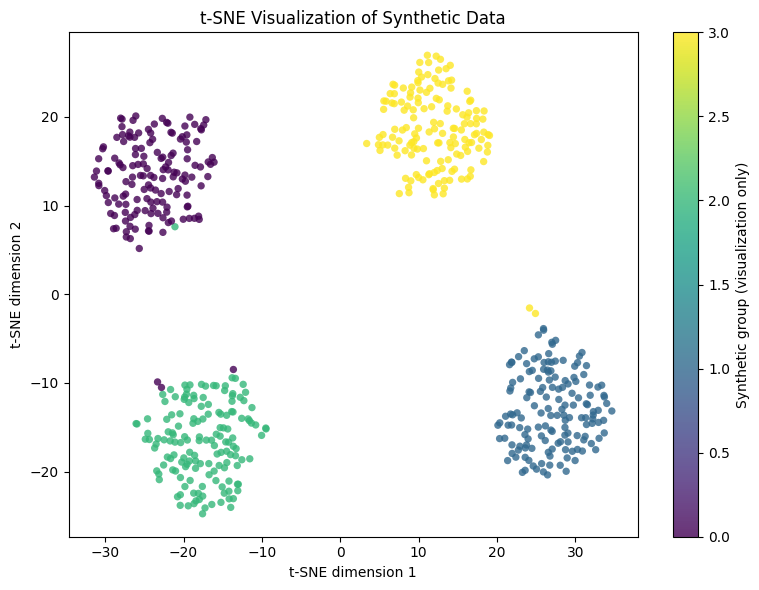

In [5]:
# Color points by synthetic labels for interpretation only.
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_tsne[:, 0], X_tsne[:, 1],
    c=y, cmap="viridis", alpha=0.8, s=28, edgecolors="none"
)
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.title("t-SNE Visualization of Synthetic Data")
plt.colorbar(scatter, label="Synthetic group (visualization only)")
plt.tight_layout()
plt.show()

## 13. Compare PCA and t-SNE

PCA emphasizes linear directions that capture variance; t-SNE emphasizes local neighborhoods. Their plots may look different without either being automatically wrong. Do not compare the raw coordinates of their axes.

C:\Users\mobin\AppData\Local\Temp\ipykernel_13824\2002678202.py:26: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


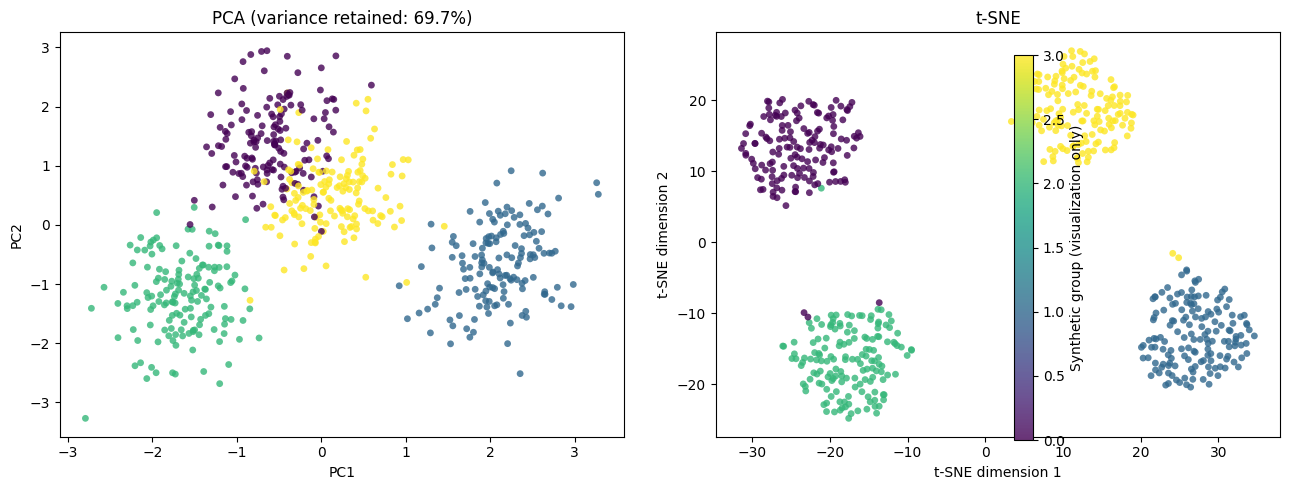

In [6]:
# Create a two-dimensional PCA projection of the same standardized samples.
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Place PCA and t-SNE plots side by side for a qualitative comparison.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
scatter = axes[0].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=y, cmap="viridis", alpha=0.8, s=24, edgecolors="none"
)
axes[0].set_title(
    f"PCA (variance retained: {pca.explained_variance_ratio_.sum():.1%})"
)
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

axes[1].scatter(
    X_tsne[:, 0], X_tsne[:, 1],
    c=y, cmap="viridis", alpha=0.8, s=24, edgecolors="none"
)
axes[1].set_title("t-SNE")
axes[1].set_xlabel("t-SNE dimension 1")
axes[1].set_ylabel("t-SNE dimension 2")

fig.colorbar(scatter, ax=axes, label="Synthetic group (visualization only)")
plt.tight_layout()
plt.show()

## 14. Experiment with Perplexity

There is no universally best perplexity. Compare plausible values while holding the data and random state constant. Do not select a value only because it creates the most visually separated groups.

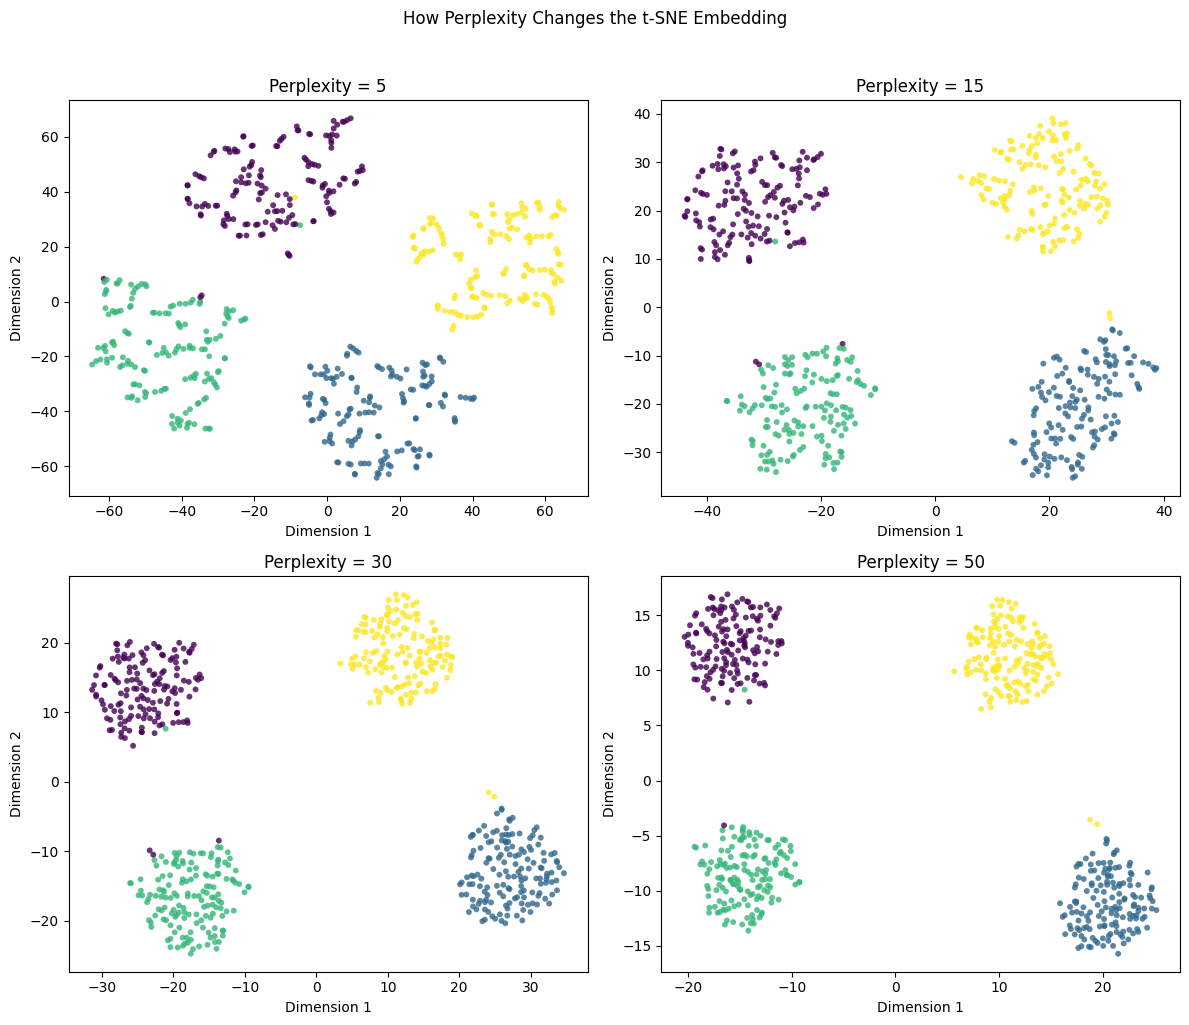

In [7]:
# Test multiple perplexity values on the same standardized dataset.
perplexities = [5, 15, 30, 50]
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for ax, perplexity in zip(axes, perplexities):
    # Each model uses the same random state for easier visual comparison.
    model = TSNE(
        n_components=2,
        perplexity=perplexity,
        learning_rate="auto",
        max_iter=1000,
        init="pca",
        random_state=RANDOM_STATE
    )
    embedding = model.fit_transform(X_scaled)

    # Use labels only to color points; they are not inputs to t-SNE.
    ax.scatter(
        embedding[:, 0], embedding[:, 1],
        c=y, cmap="viridis", s=18, alpha=0.8, edgecolors="none"
    )
    ax.set_title(f"Perplexity = {perplexity}")
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")

plt.suptitle("How Perplexity Changes the t-SNE Embedding", y=1.02)
plt.tight_layout()
plt.show()

## 15. Run-to-Run Variability

Different seeds or initialization choices may produce different layouts. Rotation, reflection, and translation are not meaningful changes by themselves; changes in local neighborhoods are more important.

For rigorous work, compare neighborhood preservation or downstream results rather than judging a plot aesthetically.

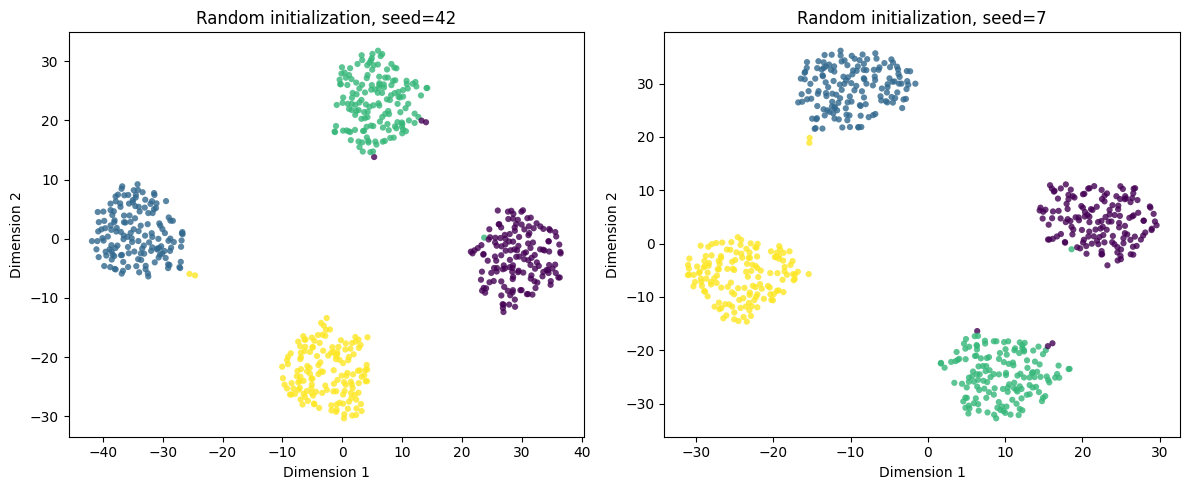

In [8]:
# Fit two embeddings with different random seeds and random initialization.
embeddings = []
for seed in [42, 7]:
    model = TSNE(
        n_components=2,
        perplexity=30,
        learning_rate="auto",
        max_iter=1000,
        init="random",
        random_state=seed
    )
    embeddings.append(model.fit_transform(X_scaled))

# Visualize both embeddings side by side.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, embedding, seed in zip(axes, embeddings, [42, 7]):
    ax.scatter(
        embedding[:, 0], embedding[:, 1],
        c=y, cmap="viridis", s=20, alpha=0.8, edgecolors="none"
    )
    ax.set_title(f"Random initialization, seed={seed}")
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")

plt.tight_layout()
plt.show()

## 16. PCA Before t-SNE for High-Dimensional Inputs

For very high-dimensional data, a common workflow is to reduce the input to a moderate number of PCA components before t-SNE. This may reduce noise and computation, but it is not always necessary and may discard information.

The five-feature dataset above does not need PCA preprocessing. The next example demonstrates the workflow on a 50-feature dataset.

Original shape: (500, 50)
After PCA: (500, 20)
After t-SNE: (500, 2)
Variance retained by PCA preprocessing: 88.27%


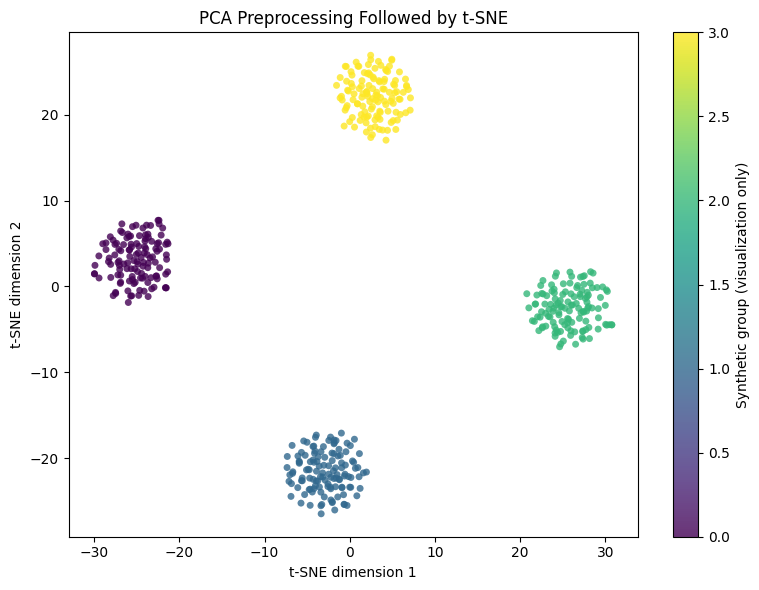

In [9]:
# Generate a higher-dimensional synthetic dataset.
X_high, y_high = make_blobs(
    n_samples=500,
    n_features=50,
    centers=4,
    cluster_std=3.0,
    random_state=RANDOM_STATE
)

# Scale features before PCA.
X_high_scaled = StandardScaler().fit_transform(X_high)

# Reduce 50 features to 20 principal components before t-SNE.
pca_pre = PCA(n_components=20, random_state=RANDOM_STATE)
X_high_pca = pca_pre.fit_transform(X_high_scaled)

# Map the PCA representation to two dimensions using t-SNE.
tsne_pre = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    max_iter=1000,
    init="pca",
    random_state=RANDOM_STATE
)
X_high_tsne = tsne_pre.fit_transform(X_high_pca)

print("Original shape:", X_high.shape)
print("After PCA:", X_high_pca.shape)
print("After t-SNE:", X_high_tsne.shape)
print("Variance retained by PCA preprocessing:",
      f"{pca_pre.explained_variance_ratio_.sum():.2%}")

# Plot the final two-dimensional embedding.
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_high_tsne[:, 0], X_high_tsne[:, 1],
    c=y_high, cmap="viridis", s=25, alpha=0.8, edgecolors="none"
)
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.title("PCA Preprocessing Followed by t-SNE")
plt.colorbar(scatter, label="Synthetic group (visualization only)")
plt.tight_layout()
plt.show()

## 17. t-SNE for Biological and Medical Data

t-SNE can help visualize samples represented by gene-expression profiles, protein measurements, medical images, or learned embeddings.

Potential uses:
- Explore sample neighborhoods.
- Inspect whether known labels or batches align with local structure.
- Visualize neural-network representations.
- Create exploratory plots to guide further analysis.

**Bioinformatics cautions**
- Normalize and transform omics data appropriately before calculating distances.
- Check whether apparent separation reflects batch, platform, tissue composition, or confounding variables.
- Do not treat a visually separated group as a validated disease subtype without independent evidence.
- Use metadata and quantitative analyses to support conclusions.
- The two axes do not represent individual genes or pathways.

## 18. Common Mistakes

1. Interpreting distances between separated clusters as precise dissimilarities.
2. Comparing cluster sizes or densities as if they were faithfully preserved.
3. Choosing perplexity solely because a plot looks attractive.
4. Forgetting that initialization and random seed affect the layout.
5. Treating t-SNE axes as original variables.
6. Assuming visible groups prove that real clusters exist.
7. Ignoring feature scales and preprocessing.
8. Treating visualization as a replacement for validation or statistical testing.
9. Expecting standard scikit-learn t-SNE to provide a conventional `transform` for unseen samples.
10. Ignoring computational cost for very large datasets.

## 19. t-SNE Cheat Sheet (`scikit-learn`)

| Parameter / attribute | Meaning |
|---|---|
| `TSNE(n_components=2)` | Create a 2D embedding |
| `perplexity=30` | Neighborhood-scale hyperparameter |
| `learning_rate="auto"` | Automatically select learning rate |
| `max_iter=1000` | Maximum optimization iterations in current versions |
| `init="pca"` | Initialize from a PCA-based layout |
| `random_state=42` | Reproducible stochastic run |
| `fit_transform(X)` | Fit t-SNE and return the embedding |
| `kl_divergence_` | Final KL divergence |
| `n_iter_` | Iterations run in versions exposing this attribute |

**Version note:** older scikit-learn releases used `n_iter`; newer releases use `max_iter`. Check `sklearn.__version__` if a parameter error occurs.

## 20. Exercises

1. Compare perplexity values 5, 10, 30, and 50.
2. Change the sample count and determine which perplexities remain valid.
3. Compare `init="pca"` with `init="random"`.
4. Compare PCA and t-SNE plots. Which properties does each emphasize?
5. Generate overlapping groups. Does t-SNE always reveal distinct clusters?
6. Compare standardized and unstandardized input.
7. Explore different learning rates while holding other settings constant.
8. Explain why distances between separated groups should not be interpreted precisely.
9. Design a quality-control checklist for a t-SNE plot of gene-expression data.
10. Explain why t-SNE is generally a visualization technique rather than a default feature transformation for predictive models.

## 21. Key Takeaways

- t-SNE is a nonlinear method mainly used for low-dimensional visualization.
- It converts similarities into probabilities and optimizes a low-dimensional embedding.
- Perplexity controls effective neighborhood scale and must be less than the sample count.
- Results depend on preprocessing, hyperparameters, initialization, and random seed.
- Local neighborhoods are usually more meaningful than distances between separated clusters.
- Cluster size, density, and gaps may be distorted.
- In biological data, combine plots with metadata, quality control, and independent evidence.

## 22. References

- Scikit-learn — TSNE API: https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html
- Scikit-learn — Manifold learning: https://scikit-learn.org/stable/modules/manifold.html
- van der Maaten, L. & Hinton, G. (2008). Visualizing Data using t-SNE. *Journal of Machine Learning Research*, 9, 2579–2605. https://www.jmlr.org/papers/v9/vandermaaten08a.html